# 04b. Tinh chỉnh, hiệu chỉnh xác suất, đánh giá cuối (Task 6)

Thứ tự bắt buộc để không "xem đề trước khi thi":

1. **Tinh chỉnh LightGBM** bằng `RandomizedSearchCV` với một lần chia theo thời gian *bên trong tập train*: fit trên mốc 2019-01, chấm trên mốc 2020-01. (Không dùng k-fold ngẫu nhiên vì cùng một khách xuất hiện ở nhiều mốc. Không fit trên 2019-07 rồi chấm trên 2020-01 vì cửa sổ nhãn của 2019-07 chồng lên năm 2020.) Nhờ vậy validation 2021-01 vẫn còn nguyên cho các bước sau.
2. **So sánh `class_weight`** với không xử lý, trên validation.
3. **Hiệu chỉnh xác suất** bằng validation. Để không tự chấm chính dữ liệu đã dùng để hiệu chỉnh: chia ngẫu nhiên validation làm hai nửa theo khách, fit bộ hiệu chỉnh trên nửa A, đo trước/sau trên nửa B; chọn phương pháp tốt hơn rồi fit lại trên toàn validation.
4. **Test 2022-01, chạy đúng một lần** (ô cuối cùng). Model cuối fit **chỉ trên train** (không gộp validation, vì validation dùng để hiệu chỉnh).

In [1]:
import sys; sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.stats import randint, uniform, loguniform
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score as AP, roc_auc_score as ROC, brier_score_loss, f1_score,
                             confusion_matrix, precision_recall_curve, roc_curve)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.calibration import calibration_curve
import viz
from churn_data import load_churn_sets, FINAL_FEATURES
from config import TRAIN_CUTOFFS, VALID_CUTOFF, TEST_CUTOFF

RNG = 0
TRAIN, va = load_churn_sets()
F = FINAL_FEATURES
yt, yv = TRAIN.churn.values, va.churn.values
print(len(F), "biến:", F)

12 biến: ['recency_days', 'frequency', 'monetary', 'mean_gap_days', 'std_gap_days', 'review_rate', 'cancel_rate', 'avg_installments', 'n_categories', 'main_source', 'main_category', 'region']


## 1. Tinh chỉnh tham số (fit 2019-01 → chấm 2020-01)

In [2]:
fitA = TRAIN[TRAIN.cutoff == TRAIN_CUTOFFS[0]]; evalA = TRAIN[TRAIN.cutoff == TRAIN_CUTOFFS[2]]
X2 = pd.concat([fitA, evalA]); cv = [(np.arange(len(fitA)), np.arange(len(fitA), len(X2)))]
space = dict(num_leaves=randint(4, 64), min_child_samples=randint(30, 600), learning_rate=loguniform(0.01, 0.1),
             n_estimators=randint(150, 700), subsample=uniform(0.6, 0.4), colsample_bytree=uniform(0.5, 0.5),
             reg_lambda=loguniform(0.1, 50), min_split_gain=uniform(0, 0.1))
base = dict(subsample_freq=1, random_state=RNG, verbose=-1, n_jobs=-1)
rs = RandomizedSearchCV(lgb.LGBMClassifier(**base), space, n_iter=40, scoring="average_precision", cv=cv,
                        random_state=RNG, refit=False, return_train_score=True)
rs.fit(X2[F], X2.churn)
res = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score")
print("Tham số mặc định (notebook 03-04) trên cùng lần chia:")
PARAMS0 = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=100, subsample=0.8, subsample_freq=1,
               colsample_bytree=0.8, reg_lambda=5, random_state=RNG, verbose=-1, n_jobs=-1)
print(round(AP(evalA.churn, lgb.LGBMClassifier(**PARAMS0).fit(fitA[F], fitA.churn).predict_proba(evalA[F])[:, 1]), 4))
res[["mean_test_score", "mean_train_score"] + [f"param_{k}" for k in space]].head(8).round(4)

Tham số mặc định (notebook 03-04) trên cùng lần chia:


0.8647


,mean_test_score,mean_train_score,param_num_leaves,param_min_child_samples,param_learning_rate,param_n_estimators,param_subsample,param_colsample_bytree,param_reg_lambda,param_min_split_gain
8,0.8649,0.8583,9,403,0.0176,455,0.7475,0.7332,0.3393,0.0656
10,0.8649,0.8635,27,400,0.0105,533,0.8755,0.7256,1.9857,0.0980
12,0.8649,0.8641,36,41,0.0208,230,0.7059,0.9646,18.6585,0.0842
18,0.8648,0.8618,28,379,0.0124,366,0.9586,0.5514,1.4601,0.0591
19,0.8648,0.8619,14,585,0.0273,362,0.9365,0.6838,1.8471,0.0100
17,0.8648,0.8566,19,499,0.0105,302,0.9514,0.8032,10.5193,0.0716
27,0.8648,0.8647,29,123,0.0151,351,0.8708,0.6889,1.9576,0.0855
21,0.8648,0.8658,31,327,0.0117,544,0.7440,0.7036,0.1076,0.0373


In [3]:
best = {k: (v.item() if hasattr(v, "item") else v) for k, v in rs.best_params_.items()}
PARAMS = {**base, **best}
print(json.dumps(best, indent=1), "\nPR-AUC chỉnh:", round(rs.best_score_, 4))
print("Chênh giữa 5 cấu hình tốt nhất:", res.mean_test_score.head(5).max() - res.mean_test_score.head(5).min())
json.dump(best, open("../reports/churn_best_params.json", "w"), indent=1)

{
 "colsample_bytree": 0.7331553864281531,
 "learning_rate": 0.01755600080155771,
 "min_child_samples": 403,
 "min_split_gain": 0.06563295894652735,
 "n_estimators": 455,
 "num_leaves": 9,
 "reg_lambda": 0.3392890920541564,
 "subsample": 0.7474900682643857
} 
PR-AUC chỉnh: 0.8649
Chênh giữa 5 cấu hình tốt nhất: 9.81735527991745e-05


## 2. `class_weight`: có xử lý lệch nhãn hay không?

Nhãn lệch vừa phải (67,5% / 32,5%). `class_weight="balanced"` làm model coi lớp thiểu số quan trọng hơn: có thể cải thiện xếp hạng, nhưng chắc chắn làm **xác suất lệch** (bước hiệu chỉnh sẽ sửa). So trên validation bằng thước đo xếp hạng (PR-AUC, ROC-AUC); Brier chỉ có nghĩa sau hiệu chỉnh nên đặt ở cột riêng.

In [4]:
rows = {}
for name, cw in [("không xử lý", None), ("balanced", "balanced")]:
    m = lgb.LGBMClassifier(**PARAMS, class_weight=cw).fit(TRAIN[F], yt); p = m.predict_proba(va[F])[:, 1]
    rows[name] = dict(PR_AUC=AP(yv, p), ROC_AUC=ROC(yv, p), Brier_chưa_hiệu_chỉnh=brier_score_loss(yv, p), p_trung_bình=p.mean())
pd.DataFrame(rows).T.round(4)

,PR_AUC,ROC_AUC,Brier_chưa_hiệu_chỉnh,p_trung_bình
không xử lý,0.8595,0.7587,0.1805,0.6445
balanced,0.8594,0.7586,0.2118,0.5011


## 3. Hiệu chỉnh xác suất

Hai phương pháp: **sigmoid** (Platt: hồi quy logistic trên logit của điểm; 2 tham số, ít linh hoạt, hợp khi lệch kiểu đơn giản) và **isotonic** (hàm bậc thang đơn điệu; linh hoạt hơn, cần nhiều dữ liệu, 26 nghìn khách mỗi nửa là đủ).

In [5]:
CW = None  # sẽ chốt dựa vào bảng ở mục 2 (xem ô kế tiếp)

In [6]:
t = pd.DataFrame(rows).T
CW = "balanced" if (t.loc["balanced", "PR_AUC"] - t.loc["không xử lý", "PR_AUC"]) > 0.002 else None
print("class_weight chọn:", CW, "(chỉ chọn balanced nếu PR-AUC hơn > 0,002; còn lại ưu tiên không xử lý vì giữ xác suất tự nhiên)")
final = lgb.LGBMClassifier(**PARAMS, class_weight=CW).fit(TRAIN[F], yt)
pv = final.predict_proba(va[F])[:, 1]

r = np.random.RandomState(RNG); half = r.rand(len(va)) < 0.5
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
def fit_cal(kind, p, y):
    if kind == "isotonic":
        m = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p, y); return m.predict
    m = LogisticRegression(C=1e6).fit(logit(p)[:, None], y); return lambda q: m.predict_proba(logit(q)[:, None])[:, 1]

def ece(y, p, bins=10):
    b = np.minimum((p * bins).astype(int), bins - 1); e = 0
    for k in range(bins):
        s = b == k
        if s.any(): e += s.mean() * abs(y[s].mean() - p[s].mean())
    return e

res = {"chưa hiệu chỉnh": pv[~half]}
for kind in ["sigmoid", "isotonic"]:
    res[kind] = fit_cal(kind, pv[half], yv[half])(pv[~half])
yB = yv[~half]
tab = pd.DataFrame({k: dict(Brier=brier_score_loss(yB, v), ECE=ece(yB, v), PR_AUC=AP(yB, v), ROC_AUC=ROC(yB, v)) for k, v in res.items()}).T
print("Đo trên nửa B của validation (bộ hiệu chỉnh fit trên nửa A):"); tab.round(4)

class_weight chọn: None (chỉ chọn balanced nếu PR-AUC hơn > 0,002; còn lại ưu tiên không xử lý vì giữ xác suất tự nhiên)


Đo trên nửa B của validation (bộ hiệu chỉnh fit trên nửa A):


,Brier,ECE,PR_AUC,ROC_AUC
chưa hiệu chỉnh,0.1810,0.0298,0.8572,0.7569
sigmoid,0.1799,0.0070,0.8572,0.7569
isotonic,0.1802,0.0093,0.8526,0.7566


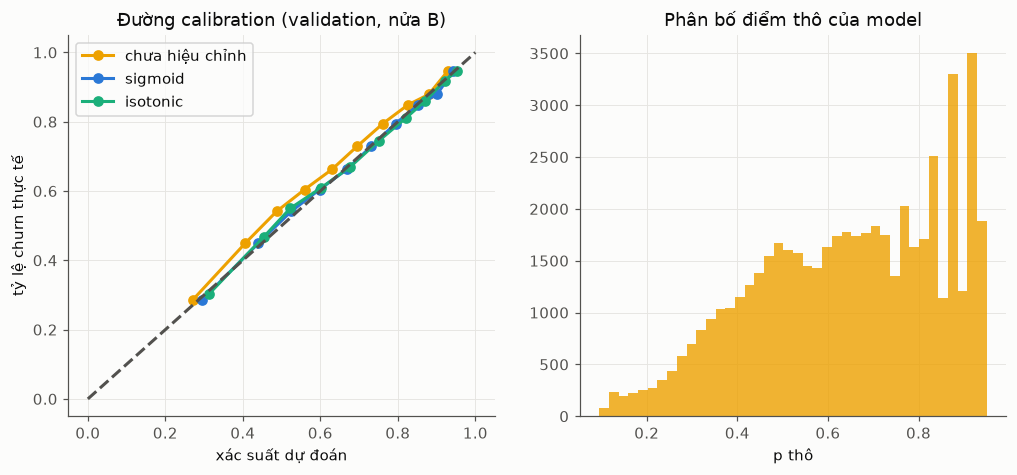

Phương pháp chọn (Brier thấp nhất trên nửa B): sigmoid


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for k, c in zip(res, [viz.C[3], viz.C[0], viz.C[2]]):
    fr, mp = calibration_curve(yB, res[k], n_bins=10, strategy="quantile"); ax[0].plot(mp, fr, "o-", color=c, label=k)
ax[0].plot([0, 1], [0, 1], "--", color=viz.INK2); ax[0].set_xlabel("xác suất dự đoán"); ax[0].set_ylabel("tỷ lệ churn thực tế")
ax[0].set_title("Đường calibration (validation, nửa B)"); ax[0].legend()
ax[1].hist(pv, bins=40, color=viz.C[3], alpha=.8); ax[1].set_title("Phân bố điểm thô của model"); ax[1].set_xlabel("p thô")
viz.save(fig, "05_calibration"); plt.show()
KIND = tab.loc[["sigmoid", "isotonic"], "Brier"].idxmin()
print("Phương pháp chọn (Brier thấp nhất trên nửa B):", KIND)
cal = fit_cal(KIND, pv, yv)   # fit lại trên toàn validation
pvc = cal(pv)

## 4. Đối chứng LogReg hiệu chỉnh (đã công bố trước ở Task 5) và ngưỡng quyết định

LogReg 12 biến được hiệu chỉnh theo cùng quy trình, để so với LightGBM trên test. **Ngưỡng** gán nhãn "sẽ churn" chọn bằng cách tối đa F1 trên validation (đã hiệu chỉnh), rồi giữ nguyên khi chạy test. Ngưỡng kinh doanh thật (theo lợi nhuận) tính ở Task 10.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from features import CATEGORICAL
def slog(X):
    X = np.asarray(X, float); return np.sign(X) * np.log1p(np.abs(X))
nums = [c for c in F if c not in CATEGORICAL]; cats = [c for c in F if c in CATEGORICAL]
lr = make_pipeline(ColumnTransformer([
    ("n", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), FunctionTransformer(slog), StandardScaler()), nums),
    ("c", OneHotEncoder(handle_unknown="ignore", min_frequency=100), cats)]), LogisticRegression(C=0.5, max_iter=500)).fit(TRAIN[F], yt)
plr = lr.predict_proba(va[F])[:, 1]
cal_lr = fit_cal(KIND, plr, yv)
ths = np.linspace(0.3, 0.9, 121)
f1s = [f1_score(yv, pvc >= th) for th in ths]
TH = float(ths[int(np.argmax(f1s))])
print(f"Ngưỡng F1 tối ưu trên validation: {TH:.3f} (F1 = {max(f1s):.4f}); ECE validation sau hiệu chỉnh (fit lại trên toàn bộ, lạc quan): {ece(yv, pvc):.4f}")

Ngưỡng F1 tối ưu trên validation: 0.420 (F1 = 0.8202); ECE validation sau hiệu chỉnh (fit lại trên toàn bộ, lạc quan): 0.0035


## 5. Kết quả trên TEST 2022-01 — chạy đúng một lần

Từ ô này trở đi **không được chỉnh lại gì** (tham số, biến, ngưỡng, bộ hiệu chỉnh đều đã đóng băng). Nếu sau này muốn đổi, phải ghi rõ là đã nhìn test.

In [9]:
from clean import clean_tables
from features import build_snapshot
from to_parquet import load_tables
te = build_snapshot(clean_tables(load_tables()), TEST_CUTOFF)
for c in CATEGORICAL:   # chỉ dùng category của train; giá trị lạ -> NaN
    te[c] = pd.Categorical(te[c].astype(str).where(te[c].notna()), categories=TRAIN[c].cat.categories)
yte = te.churn.values
p_raw = final.predict_proba(te[F])[:, 1]; p_cal = cal(p_raw)
p_lr = cal_lr(lr.predict_proba(te[F])[:, 1])
print("Test:", te.shape, "tỷ lệ churn", yte.mean().round(3))

def gain(y, s, frac):
    n = int(frac * len(y)); return y[np.argsort(-s, kind="stable")[:n]].sum() / y.sum()
rows = {}
for name, s in [("LightGBM thô", p_raw), ("LightGBM hiệu chỉnh", p_cal), ("LogReg hiệu chỉnh", p_lr)]:
    rows[name] = dict(PR_AUC=AP(yte, s), ROC_AUC=ROC(yte, s), Brier=brier_score_loss(yte, s), ECE=ece(yte, s),
                      F1_ngưỡng=f1_score(yte, s >= TH), Recall_20=gain(yte, s, .2))
rows["Ngẫu nhiên (tham chiếu)"] = dict(PR_AUC=yte.mean(), ROC_AUC=0.5, Brier=yte.mean() * (1 - yte.mean()), ECE=np.nan, F1_ngưỡng=np.nan, Recall_20=0.2)
test_tab = pd.DataFrame(rows).T; test_tab.round(4)

Test: (45880, 39) tỷ lệ churn 0.648


,PR_AUC,ROC_AUC,Brier,ECE,F1_ngưỡng,Recall_20
LightGBM thô,0.8428,0.7549,0.1875,0.0292,0.8012,0.2803
LightGBM hiệu chỉnh,0.8428,0.7549,0.1865,0.0039,0.8034,0.2803
LogReg hiệu chỉnh,0.8429,0.7551,0.1865,0.0063,0.8028,0.2800
Ngẫu nhiên (tham chiếu),0.6479,0.5000,0.2281,NaN,NaN,0.2000


PR-AUC CI95 (bootstrap): {'LightGBM hiệu chỉnh': array([0.8391, 0.8469]), 'LogReg hiệu chỉnh': array([0.8392, 0.8471])}
Ngưỡng 0.420: precision 0.707, recall 0.930


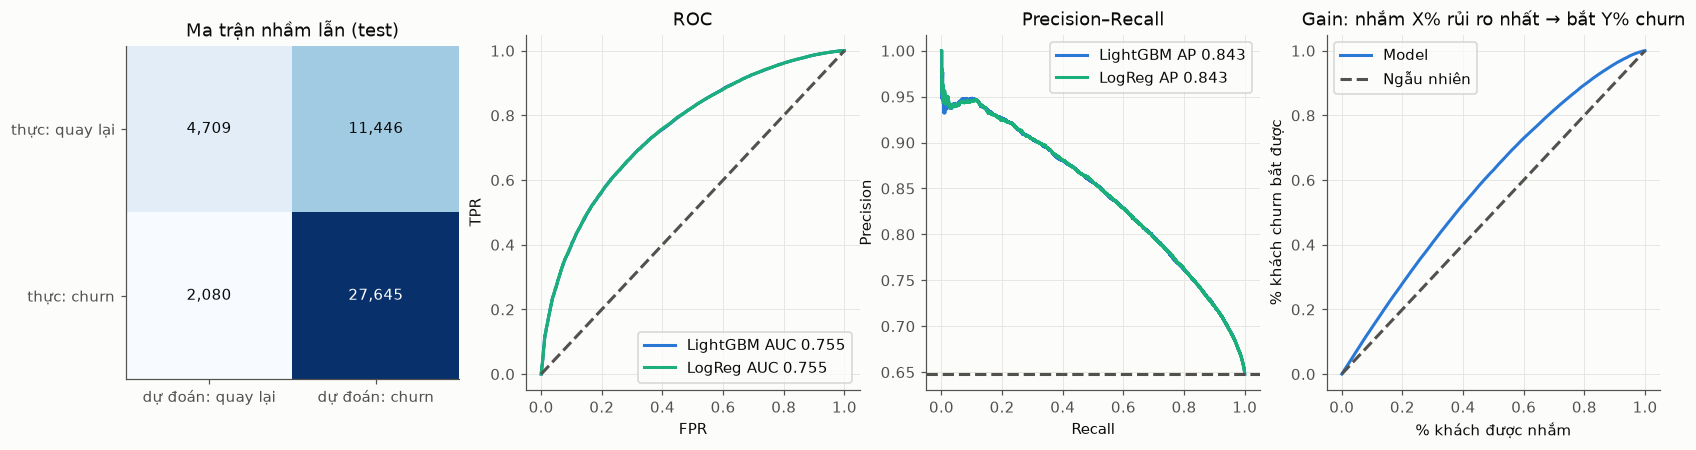

,nhắm top,bắt được % churn,lift,precision
0,10%,14.5,1.45,0.937
1,20%,28.0,1.40,0.908
2,30%,40.7,1.36,0.879
3,50%,63.1,1.26,0.817


In [10]:
lo = {}
for name, s in [("LightGBM hiệu chỉnh", p_cal), ("LogReg hiệu chỉnh", p_lr)]:
    rr = np.random.RandomState(RNG); a = [AP(yte[i], s[i]) for i in (rr.randint(0, len(yte), len(yte)) for _ in range(200))]
    lo[name] = np.percentile(a, [2.5, 97.5]).round(4)
print("PR-AUC CI95 (bootstrap):", lo)
pred = p_cal >= TH; cm = confusion_matrix(yte, pred)
print(f"Ngưỡng {TH:.3f}: precision {cm[1,1]/cm[:,1].sum():.3f}, recall {cm[1,1]/cm[1].sum():.3f}")
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
ax[0].imshow(cm, cmap="Blues"); ax[0].grid(False)
for i in range(2):
    for j in range(2): ax[0].text(j, i, f"{cm[i,j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else viz.INK)
ax[0].set_xticks([0, 1], ["dự đoán: quay lại", "dự đoán: churn"]); ax[0].set_yticks([0, 1], ["thực: quay lại", "thực: churn"]); ax[0].set_title("Ma trận nhầm lẫn (test)")
for name, s, c in [("LightGBM", p_cal, viz.C[0]), ("LogReg", p_lr, viz.C[2])]:
    f, t_, _ = roc_curve(yte, s); ax[1].plot(f, t_, color=c, label=f"{name} AUC {ROC(yte, s):.3f}")
    pr, rc, _ = precision_recall_curve(yte, s); ax[2].plot(rc, pr, color=c, label=f"{name} AP {AP(yte, s):.3f}")
ax[1].plot([0, 1], [0, 1], "--", color=viz.INK2); ax[1].set_title("ROC"); ax[1].legend(); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
ax[2].axhline(yte.mean(), ls="--", color=viz.INK2); ax[2].set_title("Precision–Recall"); ax[2].legend(); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision")
fr = np.linspace(0, 1, 101); g = [gain(yte, p_cal, x) for x in fr]
ax[3].plot(fr, g, color=viz.C[0], label="Model"); ax[3].plot(fr, fr, "--", color=viz.INK2, label="Ngẫu nhiên")
ax[3].set_title("Gain: nhắm X% rủi ro nhất → bắt Y% churn"); ax[3].set_xlabel("% khách được nhắm"); ax[3].set_ylabel("% khách churn bắt được"); ax[3].legend()
viz.save(fig, "05_test_eval"); plt.show()
lift = pd.DataFrame({"nhắm top": [f"{int(x*100)}%" for x in (.1, .2, .3, .5)],
                     "bắt được % churn": [round(gain(yte, p_cal, x) * 100, 1) for x in (.1, .2, .3, .5)],
                     "lift": [round(gain(yte, p_cal, x) / x, 2) for x in (.1, .2, .3, .5)],
                     "precision": [round(yte[np.argsort(-p_cal, kind='stable')[:int(x*len(yte))]].mean(), 3) for x in (.1, .2, .3, .5)]}); lift

## 6. Độ ổn định theo mốc cắt

Test chỉ chạy một lần nên không thêm mốc test. Bảng dưới so cùng cấu hình tham số trên các tình huống "đứng ở một mốc, đoán 12 tháng sau": mốc dò tham số (fit 2019-01 → 2020-01), validation (model cuối) và test (model cuối). Cột `lift@20%` = tỷ lệ churn trong 20% khách điểm cao nhất / tỷ lệ chung.

In [11]:
mA = lgb.LGBMClassifier(**PARAMS, class_weight=CW).fit(fitA[F], fitA.churn); pA = mA.predict_proba(evalA[F])[:, 1]
rows = []
for name, y_, s_ in [("2020-01 (fit chỉ 2019-01)", evalA.churn.values, pA), ("2021-01 validation (model cuối)", yv, pvc), ("2022-01 test (model cuối)", yte, p_cal)]:
    rows.append(dict(tình_huống=name, tỷ_lệ_churn=y_.mean(), PR_AUC=AP(y_, s_), ROC_AUC=ROC(y_, s_), lift_20=gain(y_, s_, .2) / .2,
                     PR_AUC_trừ_tỷ_lệ_churn=AP(y_, s_) - y_.mean()))
stab = pd.DataFrame(rows).set_index("tình_huống"); stab.round(4)

,tỷ_lệ_churn,PR_AUC,ROC_AUC,lift_20,PR_AUC_trừ_tỷ_lệ_churn
tình_huống,,,,,
2020-01 (fit chỉ 2019-01),0.6873,0.8649,0.7610,1.3391,0.1776
2021-01 validation (model cuối),0.6745,0.8595,0.7587,1.3577,0.1849
2022-01 test (model cuối),0.6479,0.8428,0.7549,1.4015,0.1949


In [12]:
json.dump({"class_weight": CW, "calibration": KIND, "threshold": TH, "params": best,
           "test": test_tab.round(4).to_dict("index")}, open("../reports/churn_final.json", "w", encoding="utf8"), indent=1, ensure_ascii=False)

## 7. Nhận xét

- **Tinh chỉnh gần như không có tác dụng:** 0,8649 sau khi chỉnh so với 0,8647 mặc định; 5 cấu hình tốt nhất chênh nhau chỉ 0,0001. Mô hình đã chạm trần của bộ biến và nhãn nhiễu, không phải do tham số. Giữ cấu hình đã chỉnh (nông hơn, `num_leaves` = 9, tốc độ học nhỏ).
- **`class_weight`:** PR-AUC 0,8594 (balanced) so với 0,8595 (không xử lý): không giúp xếp hạng, lại làm xác suất lệch (trung bình 0,50 so với tỷ lệ thật 0,67; Brier 0,212 so với 0,181). Chọn **không xử lý**.
- **Hiệu chỉnh:** sigmoid tốt hơn isotonic (ECE nửa B 0,007 so với 0,009, Brier thấp hơn, và không làm giảm PR-AUC như isotonic: 0,8572 so với 0,8526, do isotonic gộp các điểm thành bậc thang). Trên test ECE giảm từ 0,029 xuống 0,004: xác suất sau hiệu chỉnh đáng tin để nhân với CLV ở Task 10.
- **Test 2022-01 (chạy một lần, tham số đóng băng):** PR-AUC 0,843 (CI95 [0,839, 0,847]), ROC-AUC 0,755, Brier 0,1865. Con số tuyệt đối thấp hơn validation (0,8595) vì tỷ lệ churn test thấp hơn (64,8% so với 67,5%, nên mốc ngẫu nhiên cũng thấp hơn). Phần vượt trội so với ngẫu nhiên lại tăng (0,195 so với 0,185), và lift@20% là 1,40 so với 1,36: không có dấu hiệu model suy giảm theo thời gian.
- **Nhắm mục tiêu:** nhắm 20% khách rủi ro nhất bắt được 28% số khách churn, độ chính xác 90,8% (so với 64,8% nền); nhắm 10% đầu độ chính xác 93,7%. Lift bị giới hạn (1,4) vì 65% khách vốn đã là churn: tập khách "rủi ro" chiếm đa số, nên giá trị của model nằm ở việc loại nhóm **ít rủi ro** và xếp theo CLV, chứ không ở việc tìm một nhóm nhỏ rất nguy hiểm.
- **LogReg hiệu chỉnh ngang LightGBM** (PR-AUC 0,8429 so với 0,8428; khác nhau không có ý nghĩa thống kê). Ngưỡng F1 tối ưu 0,42 cho recall 0,93 và precision 0,71: ngưỡng này chỉ minh họa, ngưỡng theo lợi nhuận tính ở Task 10.
- **Ổn định:** PR-AUC trừ tỷ lệ nền là 0,178 / 0,185 / 0,195 qua ba tình huống, ROC-AUC 0,761 / 0,759 / 0,755 (giảm nhẹ dần).